In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("../pliki/water-potability.csv")
df

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
...,...,...,...,...,...,...,...,...,...,...
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,NaN,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,NaN,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,NaN,402.883113,11.168946,77.488213,4.708658,1


In [2]:
X = df.drop(columns=["Potability"])
X = X.select_dtypes(include=[np.number])

y=df["Potability"]

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [5]:
df.isna().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

In [6]:
df.isna().mean()

ph                 0.149878
Hardness           0.000000
Solids             0.000000
Chloramines        0.000000
Sulfate            0.238400
Conductivity       0.000000
Organic_carbon     0.000000
Trihalomethanes    0.049451
Turbidity          0.000000
Potability         0.000000
dtype: float64

### uzupełniamy medianą

In [7]:
X_train["ph"] = X_train["ph"].fillna(X_train["ph"].median())
X_train["Sulfate"] = X_train["Sulfate"].fillna(X_train["Sulfate"].median())
X_train["Trihalomethanes"] = X_train["Trihalomethanes"].fillna(X_train["Trihalomethanes"].median())

X_test["ph"] = X_test["ph"].fillna(X_train["ph"].median())
X_test["Sulfate"] = X_test["Sulfate"].fillna(X_train["Sulfate"].median())
X_test["Trihalomethanes"] = X_test["Trihalomethanes"].fillna(X_train["Trihalomethanes"].median())

X_train.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
2214,7.822492,208.636720,22308.821729,5.850328,408.123255,502.789396,16.135732,60.393982,3.835332
1634,6.037428,227.033994,12988.791229,8.476905,392.380529,306.386283,7.122391,41.190507,3.594217
2605,8.445219,228.522860,28966.569327,6.179855,333.073546,361.705354,14.554220,60.612230,4.400706
114,6.745307,218.424637,21871.838700,7.165509,333.073546,373.050102,16.826619,74.086080,3.902353
129,6.506488,202.285938,17087.076902,6.201983,326.662368,481.771934,16.535186,46.205748,3.548776


In [8]:
df.isna().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


### Skalowanie Z-score

In [11]:
from sklearn.preprocessing import StandardScaler

standard = StandardScaler()

X_train[X_train.columns]= standard.fit_transform(X_train)
X_test[X_test.columns]= standard.transform(X_test)
X_train.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
2214,0.505288,0.371295,0.048040,-0.791809,2.052308,0.925183,0.565242,-0.365393,-0.177457
1634,-0.709433,0.935084,-1.016080,0.850917,1.617777,-1.501693,-2.169448,-1.581404,-0.486502
2605,0.929048,0.980710,0.808192,-0.585714,-0.019216,-0.818137,0.085404,-0.351573,0.547202
114,-0.227728,0.671248,-0.001853,0.030738,-0.019216,-0.677955,0.774861,0.501623,-0.091554
129,-0.390242,0.176673,-0.548156,-0.571875,-0.196177,0.665479,0.686438,-1.263826,-0.544746


### trenowanie modelu

In [12]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=100, class_weight="balanced", random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

### ocena modelu
#### accuracy

In [13]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

acc = accuracy_score(y_test, y_pred)
acc

0.524390243902439

### precision

In [14]:
pre = precision_score(y_test, y_pred, zero_division=0)
pre

0.4146341463414634

#### recall

In [15]:
rec = recall_score(y_test, y_pred)
rec

0.53125

### F1-Score

In [16]:
f1 = f1_score(y_test, y_pred)
f1

0.4657534246575342

#### AUC

In [17]:
auc = roc_auc_score(y_test, y_prob)
auc

0.5474316406249999

### Roc

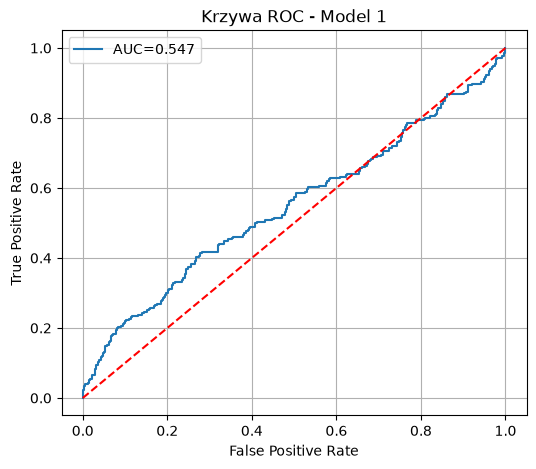

In [18]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Krzywa ROC - Model 1")
plt.legend()
plt.grid()
plt.show()

#### macierz pomyłek

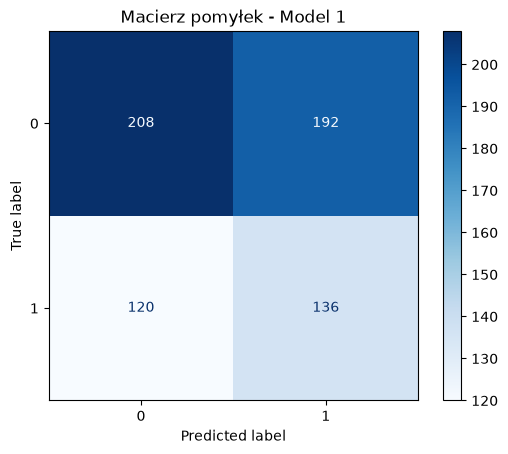

In [19]:
ConfusionMatrixDisplay(confusion_matrix(y_test,y_pred)).plot(cmap="Blues")
plt.title("Macierz pomyłek - Model 1")
plt.show()